# Neural Networks: An Introduction

Throughout this course we have built models one idea at a time: straight lines, regularised lines, trees, kernels and Gaussian processes. In this last chapter we meet a model family that is built from a very small idea repeated many times: the **artificial neuron**. When you stack enough of them together you get a **neural network**, the "framework" on which modern deep learning is built.

This chapter is optional - an extra bit of material for you to begin to see what deep learning is and how it is different to the classical machine learning that you have learnt throughout this course.

:::{admonition} What you will be able to do after this chapter
:class: tip
- Describe what a single artificial neuron computes, and recognise linear and logistic regression as special cases.
- Explain why neural networks need **non-linear activation functions**.
- Read a network diagram and count its trainable **weights** and **biases**.
- Explain, in words and with a little calculus, how **gradient descent** and **backpropagation** train a network.
- Train and evaluate a small neural network in scikit-learn, and explain why **feature scaling** and **validation** matter so much here.
:::

:::{note}
This chapter is an introduction. Specialised deep-learning architectures (CNNs, transformers, graph networks and generative models) get a short preview in the next notebook and are covered properly in a later course.
:::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'png'

# Shared look for every figure in this notebook
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#dddcd7"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "lines.linewidth": 2, "font.size": 10,
})

## 1. A loose inspiration: how we recognise things

When light from an object reaches your eye, the brain does not recognise the object in one step. Brain-imaging studies show that early visual areas respond first, and information is passed on and combined through several stages before you "know" what you are looking at. Simple features (edges, contrast) are combined into more complex ones (shapes, textures), and finally into a whole object.

Artificial neural networks borrow this **idea of layers that build complex features from simple ones**. That is where the borrowing ends.

:::{admonition} An analogy, not a model of the brain
:class: note
An artificial neuron is a few lines of arithmetic. Real neurons are far more complex. The name is historical: early work by McCulloch and Pitts (1943) and Rosenblatt's *perceptron* (1958) was inspired by biology, but modern neural networks are best understood simply as flexible mathematical functions with many adjustable numbers.
:::

## 2. One neuron: a straight line with a twist

You already know the first half of a neuron in a different context. Take some inputs (features) $x_1, x_2, x_3$, multiply each by a **weight**, add them up, and add a **bias**:

$$
z = w_1 x_1 + w_2 x_2 + w_3 x_3 + b
$$

This is exactly the linear-regression equation from earlier in the course. The weights play the role of the regression coefficients, and the bias is the intercept.

The twist is the second half. The neuron passes $z$ through an **activation function** $\sigma$:

$$
a = \sigma(z) = \sigma\left(w_1 x_1 + w_2 x_2 + w_3 x_3 + b\right)
$$

The output $a$ is called the neuron's **activation**. In words: *data is multiplied by weights, a bias is added, and the result is transformed by an activation function.*

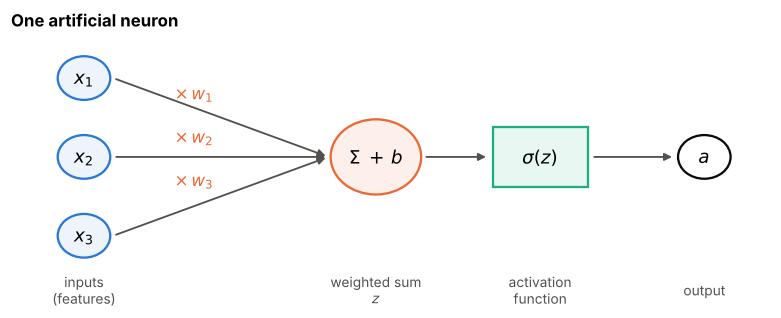

In [2]:
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.set_axis_off(); ax.set_xlim(0, 10.4); ax.set_ylim(-0.3, 4)
inputs = [(1, 3.3), (1, 2.0), (1, 0.7)]
for i, (x0, y0) in enumerate(inputs):
    ax.add_patch(plt.Circle((x0, y0), 0.36, fc="#eef4fc", ec=BLUE, lw=1.5))
    ax.text(x0, y0, f"$x_{i+1}$", ha="center", va="center", fontsize=12)
    ax.annotate("", xy=(4.35, 2.0), xytext=(x0 + 0.4, y0),
                arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2))
    xm, ym = x0 + 0.45 * (4.35 - x0), y0 + 0.45 * (2.0 - y0)
    ax.text(xm, ym + 0.22, f"$\\times\\, w_{i+1}$", color=ORANGE, fontsize=11, ha="center")
ax.add_patch(plt.Circle((5.0, 2.0), 0.62, fc="#fdf0ea", ec=ORANGE, lw=1.5))
ax.text(5.0, 2.0, "$\\Sigma\\;+\\,b$", ha="center", va="center", fontsize=12)
ax.annotate("", xy=(6.55, 2.0), xytext=(5.65, 2.0), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2))
ax.add_patch(plt.Rectangle((6.6, 1.5), 1.3, 1.0, fc="#e8f7f1", ec=AQUA, lw=1.5))
ax.text(7.25, 2.0, "$\\sigma(z)$", ha="center", va="center", fontsize=12)
ax.annotate("", xy=(9.1, 2.0), xytext=(7.95, 2.0), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2))
ax.add_patch(plt.Circle((9.5, 2.0), 0.36, fc="white", ec=INK, lw=1.5))
ax.text(9.5, 2.0, "$a$", ha="center", va="center", fontsize=12)
for x0, lab in [(1, "inputs\n(features)"), (5.0, "weighted sum\n$z$"), (7.25, "activation\nfunction"), (9.5, "output")]:
    ax.text(x0, -0.2, lab, ha="center", va="center", color=MUTED, fontsize=9)
ax.set_title("One artificial neuron", loc="left")
plt.tight_layout(); plt.show()

:::{admonition} You have already met two neurons
:class: tip
- If the activation function does nothing, $\sigma(z) = z$, a single neuron **is linear regression**.
- If the activation function is the S-shaped sigmoid function, $\sigma(z) = 1/(1+e^{-z})$, a single neuron **is logistic regression**.

So a neural network is not a strange new object. It is many small regression-like units wired together.
:::

## 3. Activation functions: where the flexibility comes from

Here are four activation functions you will see often.

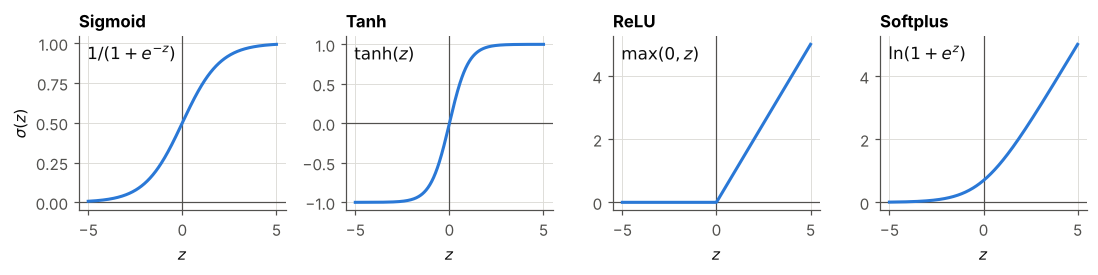

In [3]:
z = np.linspace(-5, 5, 400)
acts = [
    ("Sigmoid", 1 / (1 + np.exp(-z)), r"$1/(1+e^{-z})$"),
    ("Tanh", np.tanh(z), r"$\tanh(z)$"),
    ("ReLU", np.maximum(0, z), r"$\max(0, z)$"),
    ("Softplus", np.logaddexp(0, z), r"$\ln(1+e^{z})$"),
]
fig, axes = plt.subplots(1, 4, figsize=(10, 2.6), sharex=True)
for ax, (name, val, formula) in zip(axes, acts):
    ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=MUTED, lw=0.8)
    ax.plot(z, val, color=BLUE)
    ax.set_title(name, loc="left")
    ax.text(0.04, 0.96, formula, transform=ax.transAxes, va="top", fontsize=11, color=INK)
    ax.set_xlabel("$z$")
axes[0].set_ylabel(r"$\sigma(z)$")
plt.tight_layout(); plt.show()

- **Sigmoid** squashes any number into the range 0 to 1 (useful for probabilities).
- **Tanh** is similar but ranges from −1 to 1.
- **ReLU** (rectified linear unit) is zero for negative inputs and a straight line for positive ones. It is simple, fast, and the default in scikit-learn's `MLPRegressor`.
- **Softplus** is a smooth version of ReLU. We use it in the worked example below because its curves are easy to see.

### Why must the activation be non-linear?

Suppose we stack two layers that use **no** activation function. The first layer computes $W_1\mathbf{x} + \mathbf{b}_1$ and the second layer computes

$$
W_2\left(W_1\mathbf{x} + \mathbf{b}_1\right) + \mathbf{b}_2 \;=\; \underbrace{(W_2W_1)}_{\text{one matrix}}\,\mathbf{x} \;+\; \underbrace{(W_2\mathbf{b}_1 + \mathbf{b}_2)}_{\text{one vector}}
$$

The result is still just one linear model. However many linear layers we stack, we only ever get a straight line (or flat plane). **The non-linear bend in the activation function is what lets a network build curves.**

## 4. Stacking neurons: the multilayer perceptron

Connect many neurons in **layers** and you get the classic "plain vanilla" neural network, the **multilayer perceptron (MLP)**.

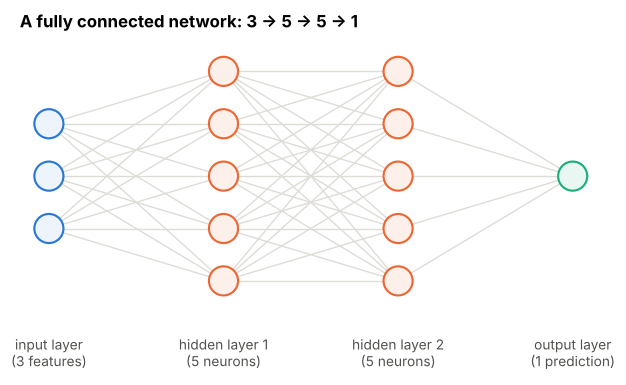

In [4]:
def draw_mlp(ax, sizes, names):
    xs = np.linspace(0.5, 9.5, len(sizes))
    pos = []
    for x, n in zip(xs, sizes):
        ys = np.linspace(-(n - 1) / 2, (n - 1) / 2, n) * 0.9
        pos.append([(x, y) for y in ys])
    for left, right in zip(pos[:-1], pos[1:]):
        for (x1, y1) in left:
            for (x2, y2) in right:
                ax.plot([x1, x2], [y1, y2], color=GRID, lw=0.9, zorder=1)
    fills = ["#eef4fc"] + ["#fdf0ea"] * (len(sizes) - 2) + ["#e8f7f1"]
    edges = [BLUE] + [ORANGE] * (len(sizes) - 2) + [AQUA]
    for layer, fc, ec in zip(pos, fills, edges):
        for (x, y) in layer:
            ax.add_patch(plt.Circle((x, y), 0.25, fc=fc, ec=ec, lw=1.4, zorder=2))
    for x, name in zip(xs, names):
        ax.text(x, -2.75, name, ha="center", va="top", color=MUTED, fontsize=9)
    ax.set_xlim(0, 10); ax.set_ylim(-3.4, 2.4); ax.set_aspect("equal"); ax.set_axis_off()

fig, ax = plt.subplots(figsize=(7.2, 3.6))
draw_mlp(ax, [3, 5, 5, 1], ["input layer\n(3 features)", "hidden layer 1\n(5 neurons)",
                            "hidden layer 2\n(5 neurons)", "output layer\n(1 prediction)"])
ax.set_title("A fully connected network: 3 → 5 → 5 → 1", loc="left")
plt.tight_layout(); plt.show()

- The **input layer** holds the features, one node per feature. It does no calculation.
- Each **hidden layer** is a row of neurons. "Hidden" simply means we never see their values in the data.
- The **output layer** gives the prediction: one node for a single property such as hardness, or one node per class in classification.
- In a **fully connected** (dense) network, every neuron receives input from every node in the layer before it. (Other designs exist; the next notebook shows some.)
- The number of hidden layers is the network's **depth**; the number of neurons per layer is its **width**. Together they set the model's **capacity**: how complicated a function it can represent.

### The same thing, written with matrices

Each line in the diagram carries its own weight, so writing every equation by hand gets long fast. With matrices, one whole layer $l$ is a single line:

$$
\mathbf{a}^{(l)} = \sigma\!\left(W^{(l)}\,\mathbf{a}^{(l-1)} + \mathbf{b}^{(l)}\right)
$$

Here $\mathbf{a}^{(l-1)}$ is the list of activations coming in from the previous layer, $W^{(l)}$ is a table of weights with one row per neuron in layer $l$, and $\mathbf{b}^{(l)}$ holds one bias per neuron. Data enters at the input layer and is passed forward, layer by layer, until it reaches the output. This is called the **forward pass**.

### Counting the knobs

Each weight and each bias is an adjustable number: think of it as a **knob**. A layer with $n_{\text{in}}$ inputs and $n_{\text{out}}$ neurons has $n_{\text{in}} \times n_{\text{out}}$ weights plus $n_{\text{out}}$ biases.

A well-known teaching example classifies handwritten digits from the MNIST database. Each image has $28 \times 28 = 784$ pixels, so the network has 784 inputs, two hidden layers of 16 neurons, and 10 outputs (one per digit):

In [5]:
layers = [784, 16, 16, 10]
total = 0
for n_in, n_out in zip(layers[:-1], layers[1:]):
    n = n_in * n_out + n_out
    total += n
    print(f"{n_in:>4} -> {n_out:<3}: {n_in}*{n_out} weights + {n_out} biases = {n:>6,}")
print(f"{'Total trainable parameters':<26}: {total:>13,}")

 784 -> 16 : 784*16 weights + 16 biases = 12,560
  16 -> 16 : 16*16 weights + 16 biases =    272
  16 -> 10 : 16*10 weights + 10 biases =    170
Total trainable parameters:        13,002


Even this small network has about thirteen thousand knobs. Compare that with the handful of coefficients in a linear regression. That flexibility is a neural network's great strength, and also the source of most of its problems (Section 9).

## 5. Walking through a tiny network

To see *how* a network builds a curve, let us use the smallest network that can do something interesting: **one input, two hidden neurons with softplus activation, and one output.**

:::{admonition} A materials picture: age hardening
:class: note
Many aluminium alloys get harder as they are aged at moderate temperature, reach a **peak hardness**, and then soften again (**over-ageing**) as precipitates coarsen. Plotted against log(ageing time), hardness rises and then falls: a hump.

The data below are **synthetic**: a smooth hump plus a little noise, on normalised axes. They mimic the *shape* of an ageing curve, not any real alloy.
:::

The network has only seven knobs:

$$
\hat{y} \;=\; w_3\,\underbrace{\text{softplus}(w_1 x + b_1)}_{a_1} \;+\; w_4\,\underbrace{\text{softplus}(w_2 x + b_2)}_{a_2} \;+\; b_3
$$

We trained it (Section 6 explains how) and then looked inside.

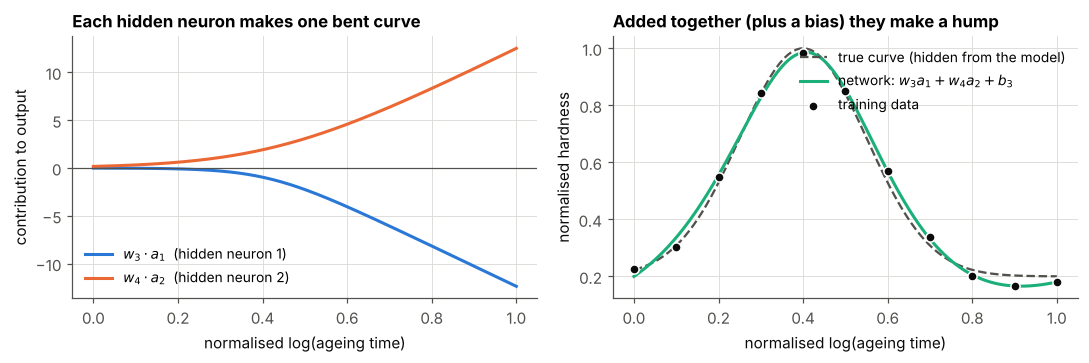

Trained knobs: w1 = +13.24  b1 = -5.49  w2 = +6.80  b2 = -2.93  w3 = -1.60  w4 = +3.22  b3 = +0.04
Sum of squared residuals (SSR) on the 11 points: 0.0021


In [6]:
def softplus(z):
    return np.logaddexp(0, z)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Synthetic 'age-hardening' data on normalised axes (illustrative only)
rng = np.random.default_rng(0)
x = np.linspace(0, 1, 11)
def true_curve(x):
    return 0.2 + 0.8 * np.exp(-((x - 0.4) ** 2) / (2 * 0.15 ** 2))
y = true_curve(x) + rng.normal(0, 0.03, x.size)

# The 1-2-1 network. Parameters p = [w1, b1, w2, b2, w3, w4, b3]
def forward(p, x):
    w1, b1, w2, b2, w3, w4, b3 = p
    z1, z2 = w1 * x + b1, w2 * x + b2
    a1, a2 = softplus(z1), softplus(z2)
    return w3 * a1 + w4 * a2 + b3, (z1, z2, a1, a2)

def ssr(p):
    return np.sum((y - forward(p, x)[0]) ** 2)

def gradients(p):
    """Backpropagation for the 1-2-1 network: dSSR/d(each knob) via the chain rule."""
    w1, b1, w2, b2, w3, w4, b3 = p
    y_pred, (z1, z2, a1, a2) = forward(p, x)
    r = -2 * (y - y_pred)                        # dSSR / dy_pred
    g_b3 = r.sum()                               # dy_pred/db3 = 1
    g_w3, g_w4 = (r * a1).sum(), (r * a2).sum()  # dy_pred/dw3 = a1, dy_pred/dw4 = a2
    d1 = r * w3 * sigmoid(z1)                    # back through softplus: d softplus/dz = sigmoid(z)
    d2 = r * w4 * sigmoid(z2)
    return np.array([(d1 * x).sum(), d1.sum(), (d2 * x).sum(), d2.sum(), g_w3, g_w4, g_b3])

def train_adam(seed, epochs=20000, lr=0.01):
    p = np.random.default_rng(seed).normal(0, 1, 7)   # random starting knobs
    m, v, hist = np.zeros(7), np.zeros(7), []
    for t in range(1, epochs + 1):
        g = gradients(p)
        m = 0.9 * m + 0.1 * g
        v = 0.999 * v + 0.001 * g ** 2
        p = p - lr * (m / (1 - 0.9 ** t)) / (np.sqrt(v / (1 - 0.999 ** t)) + 1e-8)
        hist.append(ssr(p))
    return p, np.array(hist)

def train_plain_gd(seed, epochs=20000, lr=0.005):
    p = np.random.default_rng(seed).normal(0, 1, 7)
    hist = []
    for _ in range(epochs):
        p = p - lr * gradients(p)
        hist.append(ssr(p))
    return p, np.array(hist)

p_fit, hist_adam = train_adam(seed=0)
w1, b1, w2, b2, w3, w4, b3 = p_fit
xx = np.linspace(0, 1, 300)
_, (_, _, A1, A2) = forward(p_fit, xx)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
ax.plot(xx, w3 * A1, color=BLUE, label=r"$w_3 \cdot a_1$  (hidden neuron 1)")
ax.plot(xx, w4 * A2, color=ORANGE, label=r"$w_4 \cdot a_2$  (hidden neuron 2)")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_title("Each hidden neuron makes one bent curve", loc="left")
ax.set_xlabel("normalised log(ageing time)"); ax.set_ylabel("contribution to output")
ax.legend(loc="lower left", fontsize=9)
ax = axes[1]
ax.plot(xx, true_curve(xx), color=MUTED, lw=1.5, ls="--", label="true curve (hidden from the model)")
ax.plot(xx, forward(p_fit, xx)[0], color=AQUA, label=r"network: $w_3a_1 + w_4a_2 + b_3$")
ax.scatter(x, y, s=36, color=INK, zorder=3, edgecolor="white", linewidth=1, label="training data")
ax.set_title("Added together (plus a bias) they make a hump", loc="left")
ax.set_xlabel("normalised log(ageing time)"); ax.set_ylabel("normalised hardness")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()

names = ["w1", "b1", "w2", "b2", "w3", "w4", "b3"]
print("Trained knobs:", "  ".join(f"{n} = {v:+.2f}" for n, v in zip(names, p_fit)))
print(f"Sum of squared residuals (SSR) on the 11 points: {ssr(p_fit):.4f}")

Read the left panel first. Neuron 1 stretches and shifts its softplus curve (using $w_1, b_1$) and then flips and scales it (using $w_3$). Neuron 2 does the same with its own knobs. Neither curve looks like a hump on its own. **Added together, plus the final bias $b_3$, they do.**

This is the central idea of a neural network: **simple bent pieces, scaled and added, can build complicated shapes.** With more neurons and more layers, the pieces can be combined into far more complex functions. In fact, mathematicians have proved that a network with just one hidden layer can approximate any reasonable continuous function as closely as you like, *if* it has enough neurons (the **universal approximation theorem**; Cybenko 1989; Hornik, Stinchcombe and White 1989). The theorem promises that good knob settings *exist*. It does not tell us how to find them, or how much data we need. That is the job of training.

## 6. How does a network learn its weights and biases?

Imagine a control panel with seven knobs and one meter that shows how wrong the predictions are. We want to turn the knobs until the meter reads as low as possible, **as efficiently as possible**. For the MNIST network there are 13,002 knobs, so random twiddling is hopeless. We need a strategy.

### Step 1: measure "how wrong" with a cost function

For regression, a natural meter is the **sum of squared residuals** (SSR), the same quantity least-squares regression minimises:

$$
\text{SSR} = \sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2
$$

(Dividing by $n$ gives the mean squared error, MSE. The best knob settings are the same either way.) This quantity is called the **cost function** or **loss function**.

### Step 2: start from random knobs

Training begins with the weights and biases set to small **random numbers**. The first predictions are therefore poor, and the cost is high.

### Step 3: gradient descent, one knob at a time

Let us freeze six knobs at their trained values and look at only the last one, the output bias $b_3$. Because $\hat{y}$ depends on $b_3$ as a simple "+ $b_3$", the SSR traces a smooth bowl as $b_3$ changes:

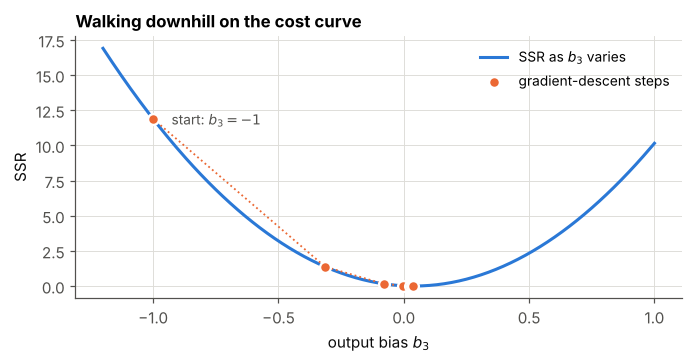

learning rate = 0.03
step        b3       SSR  slope dSSR/db3  step size
   0   -1.0000   11.8880        -22.8687    -0.6861
   1   -0.3139    1.3762         -7.7754    -0.2333
   2   -0.0807    0.1610         -2.6436    -0.0793
   3   -0.0014    0.0205         -0.8988    -0.0270
   4    0.0256    0.0043         -0.3056    -0.0092
   5    0.0348    0.0024         -0.1039    -0.0031
   6    0.0379    0.0022         -0.0353    -0.0011


In [7]:
def ssr_vs_b3(B):
    q = p_fit.copy(); q[6] = B
    return ssr(q)

lr, B = 0.03, -1.0
steps = []
for k in range(7):
    q = p_fit.copy(); q[6] = B
    slope = np.sum(-2 * (y - forward(q, x)[0]))      # dSSR/db3
    steps.append((k, B, ssr_vs_b3(B), slope, lr * slope))
    B = B - lr * slope

Bgrid = np.linspace(-1.2, 1.0, 300)
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(Bgrid, [ssr_vs_b3(v) for v in Bgrid], color=BLUE, label="SSR as $b_3$ varies")
sx = [s[1] for s in steps]; sy = [s[2] for s in steps]
ax.plot(sx, sy, color=ORANGE, lw=1.2, ls=":")
ax.scatter(sx, sy, s=50, color=ORANGE, edgecolor="white", linewidth=1.5, zorder=3, label="gradient-descent steps")
ax.annotate("start: $b_3 = -1$", (sx[0], sy[0]), xytext=(12, -4), textcoords="offset points", fontsize=9, color=MUTED)
ax.set_xlabel("output bias $b_3$"); ax.set_ylabel("SSR")
ax.set_title("Walking downhill on the cost curve", loc="left")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print(f"learning rate = {lr}")
print(f"{'step':>4} {'b3':>9} {'SSR':>9} {'slope dSSR/db3':>15} {'step size':>10}")
for k, Bk, s, g, st in steps:
    print(f"{k:>4} {Bk:>9.4f} {s:>9.4f} {g:>15.4f} {st:>10.4f}")

Gradient descent follows a simple recipe:

1. Work out the **slope** of the cost curve at the current knob setting, $\dfrac{d\,\text{SSR}}{d\,b_3}$.
2. Take a step **downhill**: $\;\text{step size} = \text{slope} \times \text{learning rate}$, and $\;b_3^{\text{new}} = b_3 - \text{step size}$.
3. Repeat. Where the curve is steep the steps are big; near the bottom the slope shrinks, so the steps shrink too.

The **learning rate** is a hyperparameter. Too small and training crawls; too large and the steps overshoot the bottom of the bowl.

### Where does the slope come from? The chain rule

$\hat{y}$ depends on $b_3$, and the SSR depends on $\hat{y}$. The chain rule from calculus links them:

$$
\frac{d\,\text{SSR}}{d\,b_3} \;=\; \frac{d\,\text{SSR}}{d\,\hat{y}} \cdot \frac{d\,\hat{y}}{d\,b_3}
\;=\; \sum_{i=1}^{n} -2\,(y_i - \hat{y}_i)\cdot 1
$$

because $\hat{y} = w_3a_1 + w_4a_2 + b_3$ gives $\dfrac{d\hat{y}}{db_3} = 1$. The same reasoning gives the slopes for the two output weights:

$$
\frac{d\,\text{SSR}}{d\,w_3} = \sum_{i=1}^{n} -2\,(y_i - \hat{y}_i)\cdot a_{1,i},
\qquad
\frac{d\,\text{SSR}}{d\,w_4} = \sum_{i=1}^{n} -2\,(y_i - \hat{y}_i)\cdot a_{2,i}
$$

since $\dfrac{d\hat{y}}{dw_3} = a_1$ and $\dfrac{d\hat{y}}{dw_4} = a_2$.

### Backpropagation: all the knobs at once

In practice we update **every** knob at the same time, each with its own slope. To reach the knobs deeper in the network ($w_1, b_1, w_2, b_2$), we keep applying the chain rule, passing the error signal **backwards** through each layer. For softplus this step is neat, because the slope of softplus is the sigmoid: $\frac{d}{dz}\ln(1+e^z) = \frac{1}{1+e^{-z}}$.

This backward flow of slopes is called **backpropagation** (popularised by Rumelhart, Hinton and Williams, 1986). One training cycle is therefore:

**forward pass** (make predictions) → **cost** (measure error) → **backward pass** (compute every slope) → **update** (nudge every knob downhill).

:::{dropdown} Show the backpropagation code used for the tiny network
The `gradients` function in the hidden code above computes all seven slopes. In outline:
```python
r   = -2 * (y - y_pred)          # dSSR/dy_pred, one value per data point
g_b3 = r.sum()                   # output bias
g_w3 = (r * a1).sum()            # output weights
g_w4 = (r * a2).sum()
d1 = r * w3 * sigmoid(z1)        # error signal passed back into neuron 1
g_w1, g_b1 = (d1 * x).sum(), d1.sum()
```
Libraries such as scikit-learn, PyTorch and TensorFlow do this bookkeeping automatically, for millions of knobs.
:::

### Plain gradient descent can stall: initialisation and optimisers matter

For the tiny network we used **Adam** (Kingma and Ba, 2015), a refinement of gradient descent that adjusts the step size for each knob separately. Adam is also scikit-learn's default. Here is why it is worth the extra sophistication:

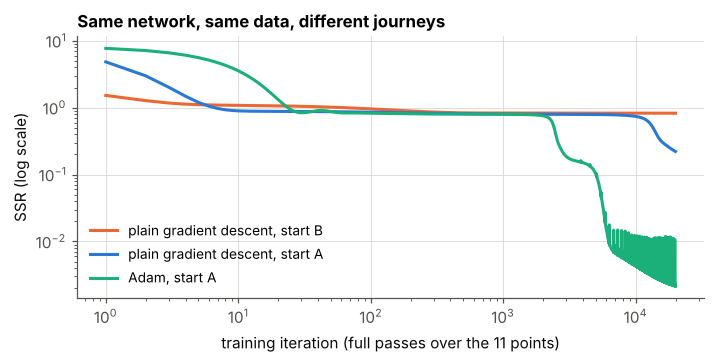

Final SSR  plain GD start A: 0.2213   plain GD start B: 0.8271   Adam start A: 0.0021


In [8]:
_, hist_gd0 = train_plain_gd(seed=0)
_, hist_gd1 = train_plain_gd(seed=1)
ep = np.arange(1, len(hist_adam) + 1)
fig, ax = plt.subplots(figsize=(6.6, 3.4))
ax.plot(ep, hist_gd1, color=ORANGE, label="plain gradient descent, start B")
ax.plot(ep, hist_gd0, color=BLUE, label="plain gradient descent, start A")
ax.plot(ep, hist_adam, color=AQUA, label="Adam, start A")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("training iteration (full passes over the 11 points)"); ax.set_ylabel("SSR (log scale)")
ax.set_title("Same network, same data, different journeys", loc="left")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
print(f"Final SSR  plain GD start A: {hist_gd0[-1]:.4f}   plain GD start B: {hist_gd1[-1]:.4f}   Adam start A: {hist_adam[-1]:.4f}")

With a fixed learning rate, plain gradient descent from random start B gets stuck on a flat region and never finds the hump. From start A it makes progress but slowly. Adam, from the same start A, reaches a much lower cost. **Where you start (the random initialisation) and how you step (the optimiser) both change the result.** This is one reason the course always fixes `random_state`.

There is a second surprise. Here is Adam again, from four different random starts:

In [9]:
print(f"{'start':>5} | {'w1':>7} {'b1':>7} {'w2':>7} {'b2':>7} {'w3':>7} {'w4':>7} {'b3':>7} | {'SSR':>7}")
for s in [0, 7, 1, 5]:
    p_s, h_s = train_adam(seed=s)
    print(f"{s:>5} | " + " ".join(f"{v:>7.2f}" for v in p_s) + f" | {h_s[-1]:>7.4f}")

start |      w1      b1      w2      b2      w3      w4      b3 |     SSR


    0 |   13.24   -5.49    6.80   -2.93   -1.60    3.22    0.04 |  0.0021


    7 |    6.73   -2.90   13.67   -5.66    3.08   -1.46    0.04 |  0.0021


    1 |   -8.34    3.25  -13.83    5.47    3.39   -2.02    0.13 |  0.0032


    5 |   -0.00   -2.06   -0.72    6.00    0.16    0.41   -1.85 |  0.8215


Three lessons are hiding in this table:

- **Starts 0 and 7** found the *same* solution, but with the two hidden neurons swapped: neuron 1 in one run does the job of neuron 2 in the other.
- **Start 1** found a genuinely different set of knobs (negative input weights) that fits the data just as well.
- **Start 5** got stuck, even with Adam. In practice people often train from several random starts and keep the one that does best on validation data.

So very different knob settings can give almost the same curve. **A network's individual weights usually have no unique physical meaning.** This is a big part of why neural networks are called "black boxes" (Section 9).

## 7. Training in practice: epochs and mini-batches

Real datasets are larger than 11 points, which changes the bookkeeping.

- An **epoch** is one complete pass through the whole training set. Training usually takes many epochs.
- Computing the exact slope using *every* data point before each step is slow for big datasets. **Stochastic gradient descent (SGD)** instead splits the data into small random **mini-batches**, computes an approximate slope from one mini-batch, takes a step, and moves on to the next mini-batch. (Strictly, "stochastic" GD uses one sample at a time and "mini-batch" GD uses a few; in practice people say SGD for both.)
- Each mini-batch step is a little less accurate, but you take many more steps for the same amount of computing, so you usually reach the bottom sooner.

:::{admonition} An analogy: walking down a foggy hill
:class: tip
Full gradient descent stops at every step to survey the whole hillside and find the exact steepest direction. Mini-batch SGD glances at the ground nearby and steps roughly downhill. Each step is less precise, but you cover ground much faster, and the small random wobbles can even help you roll past small dips.
:::

### When should training stop?

Keep training for long enough and a flexible network will start to **memorise the noise** in the training data: training error keeps falling while error on new data stops improving or gets worse. This is overfitting, the high-variance side of the **bias–variance trade-off** you met earlier. We spot it the same way as before: by holding back **validation** data that the network never trains on.

## 8. Your first neural network in scikit-learn

Scikit-learn provides a fully connected network as `MLPRegressor` (and `MLPClassifier` for classification). It follows exactly the same fit–predict workflow as every other model in this course.

We extend the age-hardening story to **two features**: ageing temperature (°C) and log₁₀ of ageing time (hours). The "true" hardness surface has a hump whose peak arrives sooner and is lower at higher temperature.

:::{note}
The dataset is **synthetic and illustrative**. The formula reproduces the qualitative trends of precipitation hardening (faster ageing and a lower peak at higher temperature), but the numbers do not describe any real alloy.
:::

In [10]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Synthetic (illustrative) age-hardening data -----------------------------
def hardness_true(T, logt):
    """'True' hardness (HV) vs ageing temperature T (degC) and log10(time / h)."""
    logt_peak = -9.0 + 4.6 * 1000 / (T + 273.15)   # hotter -> peak arrives sooner
    h_peak = 60 + 0.4 * (250 - T)                   # hotter -> lower peak
    return 60 + h_peak * np.exp(-(logt - logt_peak) ** 2 / (2 * 0.6 ** 2))

rng = np.random.default_rng(0)
T = rng.uniform(150, 250, 400)                        # ageing temperature, degC
logt = rng.uniform(-1, 3, 400)                        # 0.1 h to 1000 h
X = np.column_stack([T, logt])
y = hardness_true(T, logt) + rng.normal(0, 3, 400)    # +/- 3 HV measurement noise

# 2. Hold out a test set -----------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

# 3. Scale the features, then a network with two hidden layers of 32 neurons -
model = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(32, 32), max_iter=3000, random_state=0),
)

# 4. Train: forward pass, cost, backpropagation and Adam all happen in .fit()
model.fit(X_train, y_train)

# 5. Evaluate on data the network has never seen ------------------------------
y_pred = model.predict(X_test)
mlp = model.named_steps["mlpregressor"]
n_knobs = sum(W.size for W in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
print(f"Trainable weights + biases : {n_knobs}")
print(f"Training samples           : {len(X_train)}")
print(f"Epochs run                 : {mlp.n_iter_}")
print(f"Test R^2                   : {r2_score(y_test, y_pred):.3f}")
print(f"Test MAE                   : {mean_absolute_error(y_test, y_pred):.2f} HV")

Trainable weights + biases : 1185
Training samples           : 300
Epochs run                 : 2362
Test R^2                   : 0.990
Test MAE                   : 2.33 HV


A few things to notice:

- `hidden_layer_sizes=(32, 32)` means two hidden layers with 32 neurons each. The input and output layers are sized automatically from the data.
- The network has **more knobs than training samples**. That would be alarming for a linear regression. It is common for neural networks, and it is exactly why a held-out test set (or cross-validation) is not optional.
- The test MAE is close to the ±3 HV noise we added, so the network has learned the underlying surface rather than the noise.

Now let us look at the predictions, and at what happens if we **leave out the scaler**.

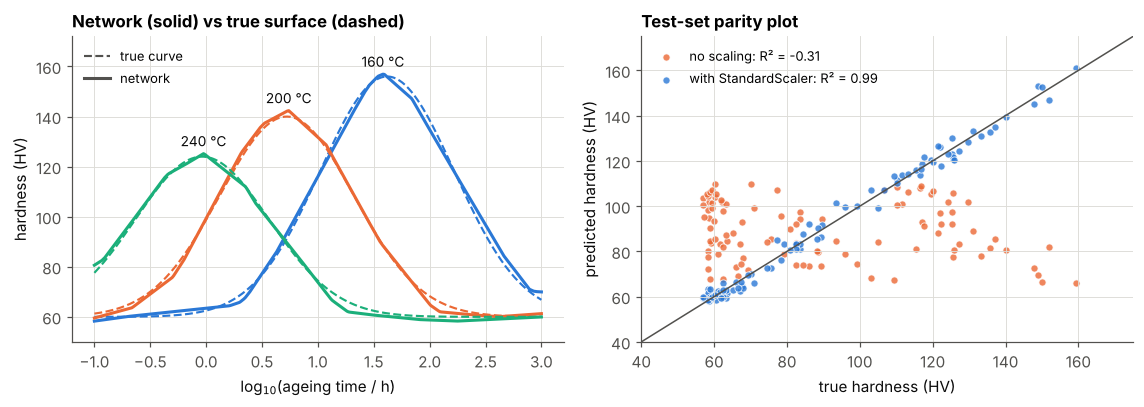

Without scaling, training stopped after 31 epochs (with scaling: 2362 epochs).


In [11]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

model_raw = MLPRegressor(hidden_layer_sizes=(32, 32), max_iter=3000, random_state=0)
model_raw.fit(X_train, y_train)
y_pred_raw = model_raw.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax = axes[0]
tt = np.linspace(-1, 3, 300)
for Tval, col in zip([160, 200, 240], [BLUE, ORANGE, AQUA]):
    ax.plot(tt, hardness_true(Tval, tt), color=col, lw=1.4, ls="--")
    pred_curve = model.predict(np.column_stack([np.full_like(tt, Tval), tt]))
    ax.plot(tt, pred_curve, color=col)
    k = pred_curve.argmax()
    ax.text(tt[k], pred_curve[k] + 3, f"{Tval} °C", color=INK, ha="center", fontsize=9)
ax.plot([], [], color=MUTED, ls="--", lw=1.4, label="true curve")
ax.plot([], [], color=MUTED, lw=2, label="network")
ax.set_ylim(50, 172)
ax.set_xlabel("log$_{10}$(ageing time / h)"); ax.set_ylabel("hardness (HV)")
ax.set_title("Network (solid) vs true surface (dashed)", loc="left")
ax.legend(fontsize=8.5, loc="upper left")

ax = axes[1]
lims = [40, 175]
ax.plot(lims, lims, color=MUTED, lw=1)
ax.scatter(y_test, y_pred_raw, s=22, color=ORANGE, alpha=0.8, edgecolor="white", linewidth=0.6,
           label=f"no scaling: R² = {r2_score(y_test, y_pred_raw):.2f}")
ax.scatter(y_test, y_pred, s=22, color=BLUE, alpha=0.8, edgecolor="white", linewidth=0.6,
           label=f"with StandardScaler: R² = {r2_score(y_test, y_pred):.2f}")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("true hardness (HV)"); ax.set_ylabel("predicted hardness (HV)")
ax.set_title("Test-set parity plot", loc="left")
ax.legend(fontsize=8.5, loc="upper left")
plt.tight_layout(); plt.show()
print(f"Without scaling, training stopped after {model_raw.n_iter_} epochs "
      f"(with scaling: {mlp.n_iter_} epochs).")

Without scaling, the network is **worse than simply predicting the average** (negative R²). Nothing else changed: same architecture, same data, same random start.

:::{admonition} Why scaling matters so much for neural networks
:class: important
You met feature scaling with distance- and penalty-based models earlier in the course. Neural networks are even more sensitive. Temperature here is in the hundreds while log-time is between −1 and 3. The starting weights are small random numbers chosen on the assumption that inputs are of order 1, so the raw temperatures produce enormous weighted sums in the first layer and badly proportioned gradient steps. The optimiser makes little progress and gives up early (only about 30 epochs above). **Always put a `StandardScaler` in a pipeline in front of an MLP.**
:::

### Watching overfitting happen, epoch by epoch

To make overfitting visible, we deliberately make life hard for the network: only **40 training samples**, a large network (two layers of 64 neurons), and **no regularisation** (`alpha=0`). After each epoch we record the error on the training samples and on held-out validation samples.

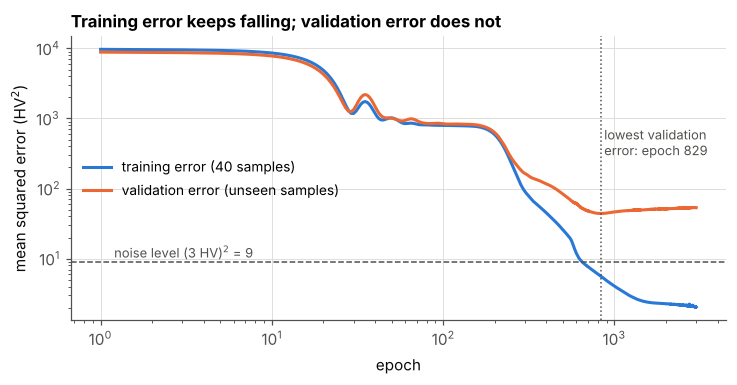

Lowest validation MSE 44.0 at epoch 829; after 3000 epochs: validation 53.5, training 2.03


In [12]:
X_small, y_small = X_train[:40], y_train[:40]
scaler = StandardScaler().fit(X_small)
Xs, Xv = scaler.transform(X_small), scaler.transform(X_test)

net = MLPRegressor(hidden_layer_sizes=(64, 64), alpha=0.0, learning_rate_init=0.01, random_state=0)
train_mse, val_mse = [], []
for epoch in range(3000):
    net.partial_fit(Xs, y_small)          # one more epoch of training
    train_mse.append(np.mean((net.predict(Xs) - y_small) ** 2))
    val_mse.append(np.mean((net.predict(Xv) - y_test) ** 2))
train_mse, val_mse = np.array(train_mse), np.array(val_mse)
best = int(val_mse.argmin())

fig, ax = plt.subplots(figsize=(6.8, 3.6))
ep = np.arange(1, 3001)
ax.plot(ep, train_mse, color=BLUE, label="training error (40 samples)")
ax.plot(ep, val_mse, color=ORANGE, label="validation error (unseen samples)")
ax.axhline(9, color=MUTED, lw=1, ls="--")
ax.text(1.2, 9 * 1.12, "noise level (3 HV)$^2$ = 9", color=MUTED, fontsize=8.5)
ax.axvline(best + 1, color=MUTED, lw=1, ls=":")
ax.text(best + 1, 300, f" lowest validation\n error: epoch {best + 1}", color=MUTED, fontsize=8.5)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("epoch"); ax.set_ylabel("mean squared error (HV$^2$)")
ax.set_title("Training error keeps falling; validation error does not", loc="left")
ax.legend(fontsize=9, loc="center left")
plt.tight_layout(); plt.show()
print(f"Lowest validation MSE {val_mse[best]:.1f} at epoch {best + 1}; "
      f"after 3000 epochs: validation {val_mse[-1]:.1f}, training {train_mse[-1]:.2f}")

Early on, both errors fall together: the network is learning the real trend. Later, the training error drops **below the noise level**. The network can only do that by bending itself to fit the random noise in those 40 points. The validation error stops improving and drifts upwards. More training is now making the model *worse* at its real job.

Three familiar tools help, and scikit-learn has all of them:

| Problem | Remedy | In `MLPRegressor` |
|---|---|---|
| Training too long | **Early stopping**: hold out part of the training data and stop when the validation score stops improving | `early_stopping=True`, `validation_fraction=0.1` |
| Weights too free | **L2 regularisation**, the same penalty as Ridge regression | `alpha` (default `0.0001`; larger = stronger) |
| Network too big for the data | Fewer or narrower layers | `hidden_layer_sizes` |

Choosing `alpha`, the layer sizes and the learning rate is **hyperparameter tuning**: use cross-validation (for example `GridSearchCV`), exactly as for any other model in this course.

## 9. Why deep networks are exciting, and why to be careful

A network with many hidden layers is called a **deep** network, hence "deep learning". It helps to weigh the strengths and limitations honestly, especially for materials science.

### Strengths

- **Representation learning.** Elsewhere in this course *you* designed the features, for example composition-based feature vectors (CBFVs). Deep networks can learn useful features directly from raw inputs, layer by layer: from atom types, to local environments, to properties.
- **Flexibility.** The universal approximation results mean a large enough network can, in principle, represent very complicated relationships.
- **Many kinds of data.** Specialised architectures handle images (micrographs), sequences (text, spectra), graphs (crystal structures) and combinations of these.
- **Generation.** Generative models can propose new candidate structures or microstructures with target properties (inverse design).
- **Transfer learning.** A model pre-trained on a large dataset can be fine-tuned on a smaller one.

### Limitations

- **Data hungry.** Thousands of knobs need lots of good data. Materials datasets are often small, biased and inconsistent, and a network may learn artefacts of the data instead of physics.
- **Low interpretability.** As Section 6 showed, individual weights rarely mean anything physical. In science, being able to explain a prediction matters.
- **Overfitting.** Especially risky with small datasets: the model may memorise known materials rather than generalise to new ones.
- **Sensitivity and reproducibility.** Results depend on scaling, random initialisation, optimiser and hyperparameters. Report them.
- **Computational and energy cost.** Training large models needs GPUs and significant energy.

:::{admonition} Practical advice for this course
:class: tip
On small **tabular** datasets (a few hundred rows of composition and processing features, which is typical in materials science), well-tuned classical models such as random forests, gradient boosting and Gaussian process regression are often as good as or better than neural networks, and easier to interpret. A large benchmark study reached a similar conclusion for tabular data in general (Grinsztajn, Oyallon and Varoquaux, 2022). **Start with a simple baseline. Reach for a neural network when you have plenty of data, or data with structure (images, sequences, graphs) that classical models cannot exploit.**
:::

## Words to listen for

| Term | Meaning in one line |
|---|---|
| **Neuron (node)** | Weighted sum of inputs plus a bias, passed through an activation function |
| **Weight** | A multiplier on one input of a neuron; a trainable knob |
| **Bias** | A constant added inside a neuron (like an intercept); a trainable knob |
| **Activation function** | The non-linear function applied to a neuron's weighted sum (ReLU, sigmoid, tanh, softplus) |
| **Layer (input / hidden / output)** | A column of nodes; hidden layers sit between the inputs and the prediction |
| **Multilayer perceptron (MLP)** | The plain, fully connected feed-forward network |
| **Fully connected (dense)** | Every node feeds every node in the next layer |
| **Depth / width** | Number of hidden layers / number of neurons per layer |
| **Forward pass** | Pushing inputs through the network to get a prediction |
| **Cost (loss) function** | A single number measuring how wrong the predictions are (SSR, MSE) |
| **Gradient descent** | Repeatedly stepping each knob downhill on the cost surface |
| **Learning rate** | The multiplier that sets how big each gradient-descent step is |
| **Backpropagation** | Using the chain rule to pass error signals backwards and get every slope |
| **Epoch** | One complete pass through the training data |
| **Mini-batch / SGD** | Updating knobs using a small random subset of data at each step |
| **Adam** | A popular gradient-descent variant that adapts the step size per knob; scikit-learn's default |
| **Early stopping** | Halting training when validation error stops improving |
| **Universal approximation** | The theorem that a wide enough network can approximate any continuous function |

## Check your understanding

**1.** A single neuron has one input and the activation function $\sigma(z) = z$. Which model from earlier in the course is it? What if $\sigma$ is the sigmoid?

:::{dropdown} Answer (instructor solution: remove before distribution)
With $\sigma(z) = z$ the neuron computes $wx + b$: **simple linear regression**. With the sigmoid it computes $1/(1+e^{-(wx+b)})$: **logistic regression**.
:::

**2.** A classmate says: "I'll skip activation functions to make my network faster; with 10 layers it will still fit curved data." What is wrong with this plan?

:::{dropdown} Answer (instructor solution: remove before distribution)
Without non-linear activations, each layer is a linear transformation, and a chain of linear transformations collapses into a single one, $W\mathbf{x} + \mathbf{b}$. Ten linear layers can only represent a straight line (or flat plane), exactly like one.
:::

**3.** How many trainable weights and biases does a fully connected network with 5 inputs, one hidden layer of 10 neurons and 1 output have?

:::{dropdown} Answer (instructor solution: remove before distribution)
Input → hidden: $5 \times 10$ weights $+ 10$ biases $= 60$. Hidden → output: $10 \times 1$ weights $+ 1$ bias $= 11$. Total **71**.
:::

**4.** In Section 8, removing `StandardScaler` made the test R² drop from about 0.99 to below zero. Using what you know about feature scaling, explain why.

:::{dropdown} Answer (instructor solution: remove before distribution)
The two features are on very different scales (temperature ~150–250, log-time ~ −1 to 3). The network's starting weights assume inputs of order 1, so raw temperatures produce huge weighted sums and badly proportioned gradients, dominated by temperature. Training stalls early and the network never learns the shape of the surface. Standardising puts both features on the same footing.
:::

**5.** During training, your training loss keeps decreasing but your validation loss starts rising after epoch 800. What is happening, and name two things you could do about it.

:::{dropdown} Answer (instructor solution: remove before distribution)
The network is **overfitting**: it is fitting noise in the training data. Remedies include early stopping (`early_stopping=True`), stronger L2 regularisation (larger `alpha`), a smaller network, or more training data.
:::

**6.** Two students train identical networks on identical data but with different `random_state` values. Both get the same test R², but their weight values are completely different. Has one of them made a mistake?

:::{dropdown} Answer (instructor solution: remove before distribution)
No. Many different weight settings can produce almost the same function. For example, swapping the roles of two hidden neurons gives an identical network with its weights rearranged. Different random starts lead gradient descent to different (equally good) solutions. This is one reason we should not read physical meaning into individual weights.
:::

## Further watching

- 3Blue1Brown, *Neural networks* video series (YouTube). A visual introduction using the MNIST digit example from Section 4.
- StatQuest with Josh Starmer, *The Essential Main Ideas of Neural Networks* and the follow-up videos on backpropagation (YouTube). A step-by-step walk-through of a small softplus network, similar in spirit to Sections 5 and 6.

## References

- Cybenko, G. (1989). Approximation by superpositions of a sigmoidal function. *Mathematics of Control, Signals and Systems*, 2, 303–314.
- Grinsztajn, L., Oyallon, E. and Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *Advances in Neural Information Processing Systems 35 (Datasets and Benchmarks Track)*.
- Hornik, K., Stinchcombe, M. and White, H. (1989). Multilayer feedforward networks are universal approximators. *Neural Networks*, 2(5), 359–366.
- Kingma, D. P. and Ba, J. (2015). Adam: A method for stochastic optimization. *International Conference on Learning Representations (ICLR)*. arXiv:1412.6980.
- LeCun, Y., Bottou, L., Bengio, Y. and Haffner, P. (1998). Gradient-based learning applied to document recognition. *Proceedings of the IEEE*, 86(11), 2278–2324.
- McCulloch, W. S. and Pitts, W. (1943). A logical calculus of the ideas immanent in nervous activity. *Bulletin of Mathematical Biophysics*, 5, 115–133.
- Rosenblatt, F. (1958). The perceptron: a probabilistic model for information storage and organization in the brain. *Psychological Review*, 65(6), 386–408.
- Rumelhart, D. E., Hinton, G. E. and Williams, R. J. (1986). Learning representations by back-propagating errors. *Nature*, 323, 533–536.
- scikit-learn documentation: [Neural network models (supervised)](https://scikit-learn.org/stable/modules/neural_networks_supervised.html).